# Model Evaluation - 577-Disease Classification

**Project:** Active Medical Chatbot with ANN-based Diagnosis System

**Date:** 2025-10-17

---

## Overview

This notebook provides comprehensive evaluation of the trained PyTorch ANN model:

- **Test Set Performance:** Overall accuracy, top-k accuracies, loss
- **Confusion Matrix:** Visualize prediction patterns
- **Per-Class Metrics:** Precision, recall, F1-score for each disease
- **Error Analysis:** Identify common misclassifications
- **Performance by Frequency:** How well does the model handle rare vs common diseases?
- **Confidence Analysis:** Distribution of prediction confidence scores

---

## Objectives

1. Evaluate model performance on unseen test data
2. Identify strengths and weaknesses
3. Analyze class-specific performance
4. Provide insights for model improvement
5. Generate publication-quality visualizations for thesis

## 1. Environment Setup

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Sklearn metrics
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
    top_k_accuracy_score, roc_auc_score
)

# Display settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("✅ Libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

✅ Libraries imported successfully
PyTorch version: 2.8.0
Device: CPU


## 2. Configuration and Paths

In [2]:
# Define paths
DATA_DIR = Path('../data/processed/common')
MODEL_DIR = Path('../models/pytorch')
OUTPUT_DIR = Path('../data/evaluation')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Device configuration
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("="*80)
print("EVALUATION CONFIGURATION")
print("="*80)
print(f"Data directory: {DATA_DIR}")
print(f"Model directory: {MODEL_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Device: {DEVICE}")

EVALUATION CONFIGURATION
Data directory: ../data/processed/common
Model directory: ../models/pytorch
Output directory: ../data/evaluation
Device: cpu


## 3. Load Test Data

In [3]:
print("📂 Loading test dataset...")

# Load test data
test_df = pd.read_csv(DATA_DIR / 'test.csv')

print(f"✅ Test dataset loaded")
print(f"   Test samples: {len(test_df):,}")
print(f"   Features: {len(test_df.columns) - 1}")
print(f"   Diseases: {test_df['disease'].nunique()}")

# Prepare features and labels
X_test = test_df.drop('disease', axis=1).values.astype('float32')
y_test_labels = test_df['disease'].values

print(f"\n📊 Test set shape: {X_test.shape}")

📂 Loading test dataset...
✅ Test dataset loaded
   Test samples: 28,327
   Features: 377
   Diseases: 577

📊 Test set shape: (28327, 377)


## 4. Load Trained Model and Label Encoder

In [4]:
# Load label encoder
print("🔧 Loading label encoder...")
with open(MODEL_DIR / 'label_encoder.pkl', 'rb') as f:
    label_encoder = pickle.load(f)

# Encode test labels
y_test = label_encoder.transform(y_test_labels)
num_classes = len(label_encoder.classes_)
input_dim = X_test.shape[1]

print(f"✅ Label encoder loaded")
print(f"   Number of classes: {num_classes}")
print(f"   Input features: {input_dim}")

🔧 Loading label encoder...
✅ Label encoder loaded
   Number of classes: 577
   Input features: 377


In [5]:
# Define model architecture (same as training)
class ANNDiseaseClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, dropout_rates=(0.3, 0.3, 0.2)):
        super(ANNDiseaseClassifier, self).__init__()
        
        self.fc1 = nn.Linear(input_dim, 512)
        self.bn1 = nn.BatchNorm1d(512)
        self.dropout1 = nn.Dropout(dropout_rates[0])
        
        self.fc2 = nn.Linear(512, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.dropout2 = nn.Dropout(dropout_rates[1])
        
        self.fc3 = nn.Linear(256, 128)
        self.bn3 = nn.BatchNorm1d(128)
        self.dropout3 = nn.Dropout(dropout_rates[2])
        
        self.fc4 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout1(x)
        
        x = self.fc2(x)
        x = self.bn2(x)
        x = self.relu(x)
        x = self.dropout2(x)
        
        x = self.fc3(x)
        x = self.bn3(x)
        x = self.relu(x)
        x = self.dropout3(x)
        
        x = self.fc4(x)
        return x

# Build and load model
print("\n🏗️  Loading trained model...")
model = ANNDiseaseClassifier(input_dim, num_classes)
model = model.to(DEVICE)

# Load best model checkpoint
checkpoint = torch.load(MODEL_DIR / 'best_model.pth', map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"✅ Model loaded successfully")
print(f"   Best epoch: {checkpoint['epoch'] + 1}")
print(f"   Validation accuracy: {checkpoint['val_acc']*100:.2f}%")
print(f"   Validation loss: {checkpoint['val_loss']:.4f}")


🏗️  Loading trained model...
✅ Model loaded successfully
   Best epoch: 77
   Validation accuracy: 83.75%
   Validation loss: 0.4244


## 5. Generate Predictions on Test Set

In [6]:
print("🔮 Generating predictions on test set...")

# Create test dataset and loader
class DiseaseDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

test_dataset = DiseaseDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Generate predictions
all_preds = []
all_probs = []
all_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

print(f"✅ Predictions generated")
print(f"   Predictions shape: {all_preds.shape}")
print(f"   Probabilities shape: {all_probs.shape}")

🔮 Generating predictions on test set...
✅ Predictions generated
   Predictions shape: (28327,)
   Probabilities shape: (28327, 577)


## 6. Overall Performance Metrics

In [7]:
print("="*80)
print("TEST SET PERFORMANCE METRICS")
print("="*80)

# Calculate metrics
test_acc = accuracy_score(all_labels, all_preds)
top3_acc = top_k_accuracy_score(all_labels, all_probs, k=3, labels=np.arange(num_classes))
top5_acc = top_k_accuracy_score(all_labels, all_probs, k=5, labels=np.arange(num_classes))
top10_acc = top_k_accuracy_score(all_labels, all_probs, k=10, labels=np.arange(num_classes))

# Macro/Micro averaged metrics
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='macro', zero_division=0
)
precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='micro', zero_division=0
)
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='weighted', zero_division=0
)

print(f"\n📊 ACCURACY METRICS:")
print(f"   Top-1 Accuracy:  {test_acc*100:.2f}%")
print(f"   Top-3 Accuracy:  {top3_acc*100:.2f}%")
print(f"   Top-5 Accuracy:  {top5_acc*100:.2f}%")
print(f"   Top-10 Accuracy: {top10_acc*100:.2f}%")

print(f"\n📊 MACRO-AVERAGED METRICS (Equal weight per class):")
print(f"   Precision: {precision_macro*100:.2f}%")
print(f"   Recall:    {recall_macro*100:.2f}%")
print(f"   F1-Score:  {f1_macro*100:.2f}%")

print(f"\n📊 MICRO-AVERAGED METRICS (Overall):")
print(f"   Precision: {precision_micro*100:.2f}%")
print(f"   Recall:    {recall_micro*100:.2f}%")
print(f"   F1-Score:  {f1_micro*100:.2f}%")

print(f"\n📊 WEIGHTED-AVERAGED METRICS (Weighted by support):")
print(f"   Precision: {precision_weighted*100:.2f}%")
print(f"   Recall:    {recall_weighted*100:.2f}%")
print(f"   F1-Score:  {f1_weighted*100:.2f}%")

# Calculate confidence statistics
max_probs = np.max(all_probs, axis=1)
print(f"\n📊 CONFIDENCE STATISTICS:")
print(f"   Mean confidence: {max_probs.mean()*100:.2f}%")
print(f"   Median confidence: {np.median(max_probs)*100:.2f}%")
print(f"   Min confidence: {max_probs.min()*100:.2f}%")
print(f"   Max confidence: {max_probs.max()*100:.2f}%")

TEST SET PERFORMANCE METRICS

📊 ACCURACY METRICS:
   Top-1 Accuracy:  83.22%
   Top-3 Accuracy:  94.82%
   Top-5 Accuracy:  97.50%
   Top-10 Accuracy: 99.19%

📊 MACRO-AVERAGED METRICS (Equal weight per class):
   Precision: 75.92%
   Recall:    85.64%
   F1-Score:  78.09%

📊 MICRO-AVERAGED METRICS (Overall):
   Precision: 83.22%
   Recall:    83.22%
   F1-Score:  83.22%

📊 WEIGHTED-AVERAGED METRICS (Weighted by support):
   Precision: 86.93%
   Recall:    83.22%
   F1-Score:  83.98%

📊 CONFIDENCE STATISTICS:
   Mean confidence: 88.19%
   Median confidence: 99.79%
   Min confidence: 7.59%
   Max confidence: 100.00%


## 7. Per-Class Performance Analysis

In [8]:
print("📋 Generating per-class metrics...")

# Get per-class metrics
precision_per_class, recall_per_class, f1_per_class, support_per_class = precision_recall_fscore_support(
    all_labels, all_preds, average=None, zero_division=0
)

# Create per-class dataframe
per_class_metrics = pd.DataFrame({
    'Disease': label_encoder.classes_,
    'Precision': precision_per_class,
    'Recall': recall_per_class,
    'F1-Score': f1_per_class,
    'Support': support_per_class
})

# Sort by F1-score descending
per_class_metrics = per_class_metrics.sort_values('F1-Score', ascending=False)

print(f"\n✅ Per-class metrics generated for {len(per_class_metrics)} diseases")
print(f"\n🏆 TOP 10 BEST PERFORMING DISEASES (by F1-Score):")
print(per_class_metrics.head(10).to_string(index=False))

print(f"\n⚠️  TOP 10 WORST PERFORMING DISEASES (by F1-Score):")
print(per_class_metrics.tail(10).to_string(index=False))

# Save per-class metrics
per_class_metrics.to_csv(OUTPUT_DIR / 'per_class_metrics.csv', index=False)
print(f"\n💾 Per-class metrics saved to: {OUTPUT_DIR / 'per_class_metrics.csv'}")

📋 Generating per-class metrics...

✅ Per-class metrics generated for 577 diseases

🏆 TOP 10 BEST PERFORMING DISEASES (by F1-Score):
                       Disease  Precision  Recall  F1-Score  Support
                 nốt ruồi nang        1.0     1.0       1.0        3
                  thận đa nang        1.0     1.0       1.0        2
                  bệnh não gan        1.0     1.0       1.0        3
suy giảm miễn dịch nguyên phát        1.0     1.0       1.0        2
            bệnh ký sinh trùng        1.0     1.0       1.0        4
        không dung nạp lactose        1.0     1.0       1.0        6
       viêm tuyến giáp bán cấp        1.0     1.0       1.0        2
       viêm đường mật tăng dần        1.0     1.0       1.0        3
       khuyết tật tim bẩm sinh        1.0     1.0       1.0        2
       bệnh thần kinh do thuốc        1.0     1.0       1.0        2

⚠️  TOP 10 WORST PERFORMING DISEASES (by F1-Score):
                  Disease  Precision   Recall  F1-Score 

## 8. Performance by Disease Frequency

In [9]:
print("📊 Analyzing performance by disease frequency...")

# Categorize diseases by sample count (support)
def categorize_frequency(support):
    if support < 50:
        return 'Very Rare (10-49)'
    elif support < 100:
        return 'Rare (50-99)'
    elif support < 200:
        return 'Moderate (100-199)'
    elif support < 500:
        return 'Common (200-499)'
    else:
        return 'Very Common (500+)'

per_class_metrics['Frequency_Category'] = per_class_metrics['Support'].apply(categorize_frequency)

# Group by frequency category
freq_analysis = per_class_metrics.groupby('Frequency_Category').agg({
    'Precision': 'mean',
    'Recall': 'mean',
    'F1-Score': 'mean',
    'Support': ['count', 'sum']
}).round(4)

freq_analysis.columns = ['Avg_Precision', 'Avg_Recall', 'Avg_F1', 'Num_Diseases', 'Total_Samples']
freq_analysis = freq_analysis.sort_values('Total_Samples', ascending=False)

print(f"\n📊 PERFORMANCE BY DISEASE FREQUENCY:")
print(freq_analysis)

# Save frequency analysis
freq_analysis.to_csv(OUTPUT_DIR / 'performance_by_frequency.csv')
print(f"\n💾 Frequency analysis saved to: {OUTPUT_DIR / 'performance_by_frequency.csv'}")

📊 Analyzing performance by disease frequency...

📊 PERFORMANCE BY DISEASE FREQUENCY:
                    Avg_Precision  Avg_Recall  Avg_F1  Num_Diseases  \
Frequency_Category                                                    
Moderate (100-199)         0.9117      0.8024  0.8468           114   
Very Rare (10-49)          0.6991      0.8722  0.7501           391   
Rare (50-99)               0.8445      0.8563  0.8442            72   

                    Total_Samples  
Frequency_Category                 
Moderate (100-199)          16163  
Very Rare (10-49)            6731  
Rare (50-99)                 5433  

💾 Frequency analysis saved to: ../data/evaluation/performance_by_frequency.csv


## 9. Confusion Matrix Analysis

In [10]:
print("🔍 Generating confusion matrix...")

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Calculate accuracy from confusion matrix
correct_predictions = np.diag(cm).sum()
total_predictions = cm.sum()
cm_accuracy = correct_predictions / total_predictions

print(f"\n✅ Confusion matrix shape: {cm.shape}")
print(f"   Correct predictions: {correct_predictions:,} / {total_predictions:,}")
print(f"   Accuracy from CM: {cm_accuracy*100:.2f}%")

# Find most confused pairs
print(f"\n🔀 TOP 10 MOST CONFUSED DISEASE PAIRS:")
confused_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            confused_pairs.append({
                'True Disease': label_encoder.classes_[i],
                'Predicted Disease': label_encoder.classes_[j],
                'Count': cm[i, j],
                'True Support': support_per_class[i]
            })

confused_df = pd.DataFrame(confused_pairs)
confused_df = confused_df.sort_values('Count', ascending=False)
print(confused_df.head(10).to_string(index=False))

# Save confusion pairs
confused_df.to_csv(OUTPUT_DIR / 'most_confused_pairs.csv', index=False)
print(f"\n💾 Confusion pairs saved to: {OUTPUT_DIR / 'most_confused_pairs.csv'}")

🔍 Generating confusion matrix...

✅ Confusion matrix shape: (577, 577)
   Correct predictions: 23,573 / 28,327
   Accuracy from CM: 83.22%

🔀 TOP 10 MOST CONFUSED DISEASE PAIRS:
                      True Disease                          Predicted Disease  Count  True Support
            viêm phế quản cấp tính        bệnh phổi tắc nghẽn mãn tính (COPD)     38           182
                      viêm túi mật                                        sỏi     37           181
     viêm dạ dày ruột truyền nhiễm         viêm dạ dày ruột không nhiễm trùng     36           182
                          polyp da                                rối loạn da     35           121
viêm dạ dày ruột không nhiễm trùng              viêm dạ dày ruột truyền nhiễm     34           181
      khô mắt không rõ nguyên nhân                          rối loạn giác mạc     32           118
                     nghiện cần sa                         rối loạn nhân cách     31           182
                     bệnh về 

## 10. Visualizations

### 10.1 Performance Metrics Overview


✅ Overview visualization saved: ../data/evaluation/evaluation_overview.png


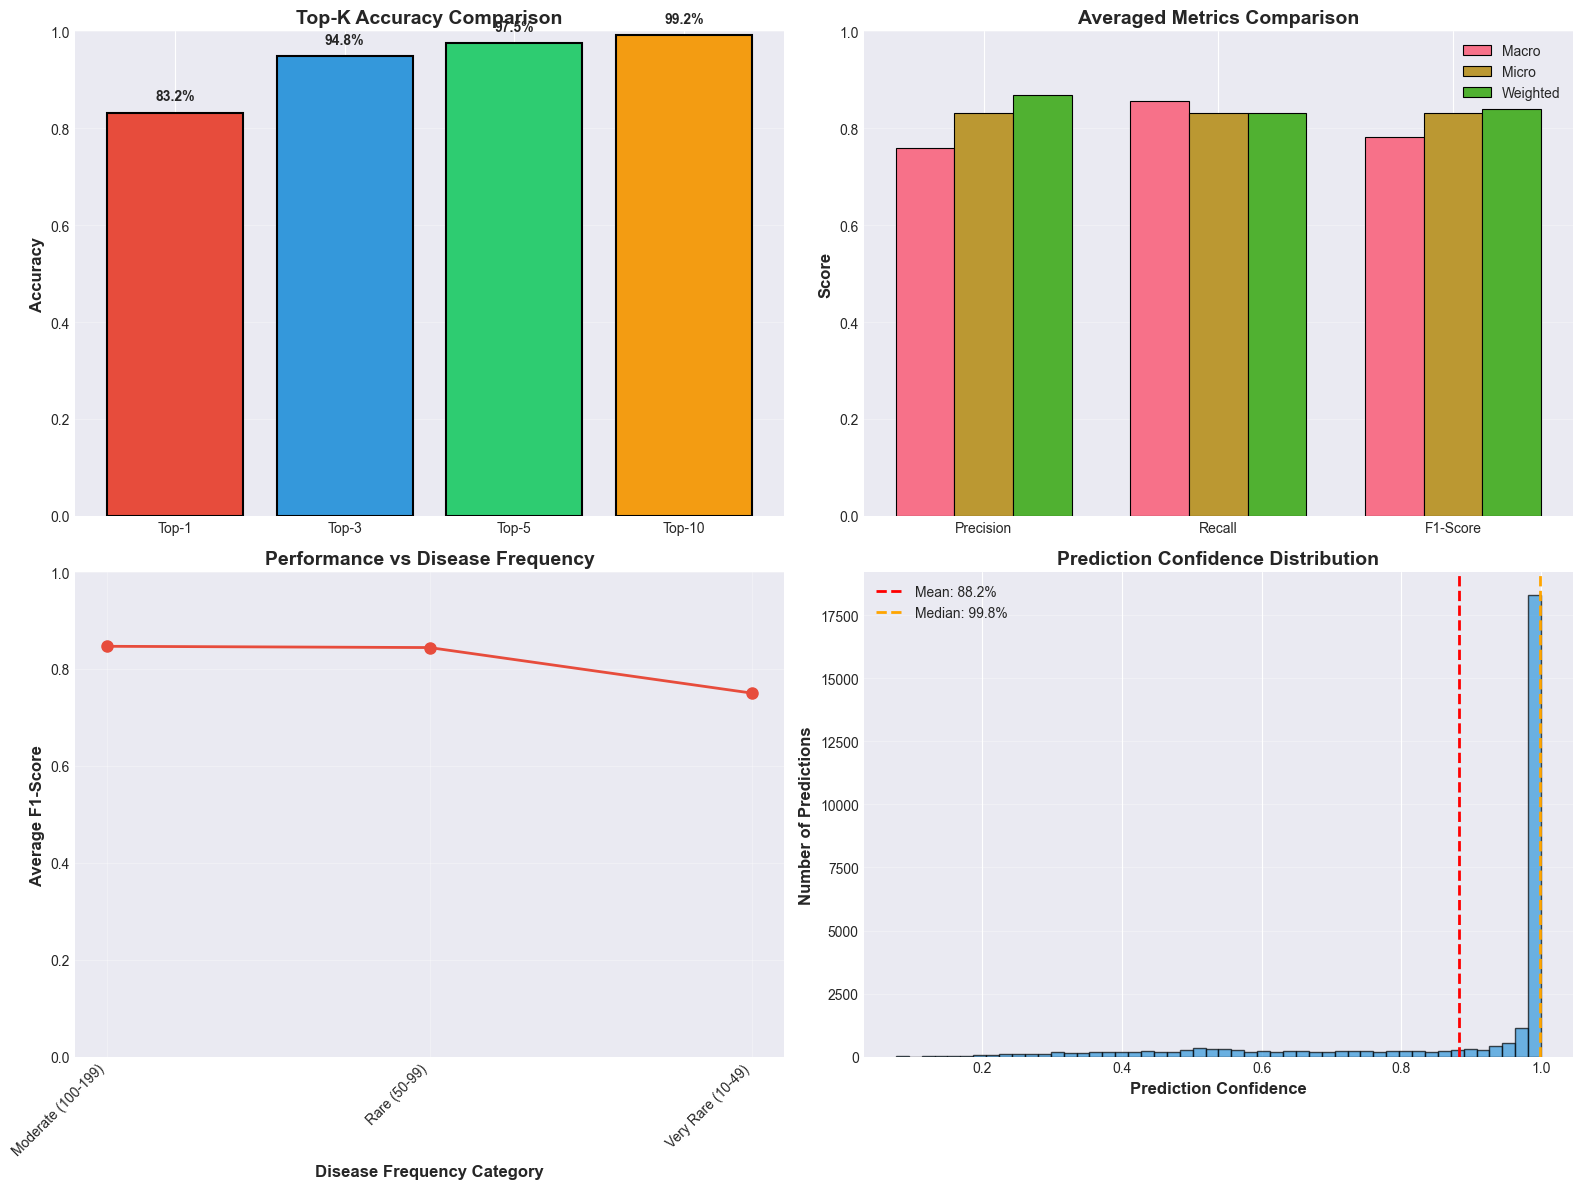

In [11]:
# Create comprehensive performance visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Accuracy Metrics
accuracies = [test_acc, top3_acc, top5_acc, top10_acc]
acc_labels = ['Top-1', 'Top-3', 'Top-5', 'Top-10']
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

bars = axes[0, 0].bar(acc_labels, accuracies, color=colors, edgecolor='black', linewidth=1.5)
axes[0, 0].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Top-K Accuracy Comparison', fontsize=14, fontweight='bold')
axes[0, 0].set_ylim([0, 1])
axes[0, 0].grid(axis='y', alpha=0.3)
for bar, acc in zip(bars, accuracies):
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height + 0.02,
                   f'{acc*100:.1f}%', ha='center', va='bottom', fontweight='bold')

# Plot 2: Macro vs Micro vs Weighted Metrics
metrics_comparison = {
    'Macro': [precision_macro, recall_macro, f1_macro],
    'Micro': [precision_micro, recall_micro, f1_micro],
    'Weighted': [precision_weighted, recall_weighted, f1_weighted]
}

x = np.arange(3)
width = 0.25
metric_labels = ['Precision', 'Recall', 'F1-Score']

for i, (avg_type, values) in enumerate(metrics_comparison.items()):
    offset = (i - 1) * width
    axes[0, 1].bar(x + offset, values, width, label=avg_type, edgecolor='black', linewidth=0.8)

axes[0, 1].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Averaged Metrics Comparison', fontsize=14, fontweight='bold')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(metric_labels)
axes[0, 1].set_ylim([0, 1])
axes[0, 1].legend()
axes[0, 1].grid(axis='y', alpha=0.3)

# Plot 3: Performance by Frequency
freq_order = ['Very Common (500+)', 'Common (200-499)', 'Moderate (100-199)', 
              'Rare (50-99)', 'Very Rare (10-49)']
freq_filtered = freq_analysis.reindex(freq_order).dropna()

x_pos = np.arange(len(freq_filtered))
axes[1, 0].plot(x_pos, freq_filtered['Avg_F1'], marker='o', linewidth=2, markersize=8, color='#e74c3c')
axes[1, 0].set_ylabel('Average F1-Score', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Disease Frequency Category', fontsize=12, fontweight='bold')
axes[1, 0].set_title('Performance vs Disease Frequency', fontsize=14, fontweight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(freq_filtered.index, rotation=45, ha='right')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0, 1])

# Plot 4: Confidence Distribution
axes[1, 1].hist(max_probs, bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[1, 1].axvline(max_probs.mean(), color='red', linestyle='--', linewidth=2, 
                  label=f'Mean: {max_probs.mean()*100:.1f}%')
axes[1, 1].axvline(np.median(max_probs), color='orange', linestyle='--', linewidth=2,
                  label=f'Median: {np.median(max_probs)*100:.1f}%')
axes[1, 1].set_xlabel('Prediction Confidence', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Number of Predictions', fontsize=12, fontweight='bold')
axes[1, 1].set_title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'evaluation_overview.png', dpi=300, bbox_inches='tight')
print(f"\n✅ Overview visualization saved: {OUTPUT_DIR / 'evaluation_overview.png'}")
plt.show()

### 10.2 Per-Class F1-Score Distribution

✅ F1-score distribution saved: ../data/evaluation/f1_score_distribution.png


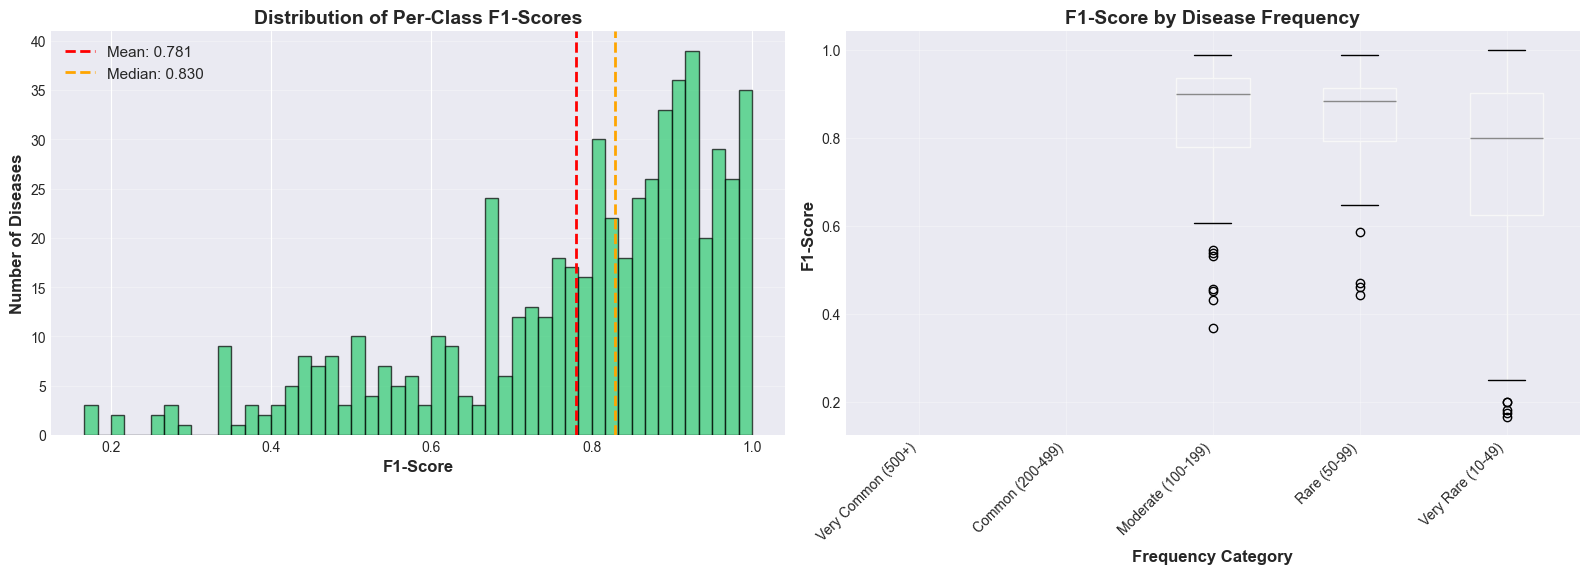

In [12]:
# Plot F1-score distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
axes[0].hist(per_class_metrics['F1-Score'], bins=50, color='#2ecc71', edgecolor='black', alpha=0.7)
axes[0].axvline(per_class_metrics['F1-Score'].mean(), color='red', linestyle='--', linewidth=2,
               label=f"Mean: {per_class_metrics['F1-Score'].mean():.3f}")
axes[0].axvline(per_class_metrics['F1-Score'].median(), color='orange', linestyle='--', linewidth=2,
               label=f"Median: {per_class_metrics['F1-Score'].median():.3f}")
axes[0].set_xlabel('F1-Score', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Diseases', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Per-Class F1-Scores', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(axis='y', alpha=0.3)

# Box plot by frequency category
freq_order_plot = ['Very Common (500+)', 'Common (200-499)', 'Moderate (100-199)', 
                   'Rare (50-99)', 'Very Rare (10-49)']
per_class_metrics['Frequency_Category'] = pd.Categorical(
    per_class_metrics['Frequency_Category'], 
    categories=freq_order_plot, 
    ordered=True
)

per_class_metrics.boxplot(column='F1-Score', by='Frequency_Category', ax=axes[1])
axes[1].set_xlabel('Frequency Category', fontsize=12, fontweight='bold')
axes[1].set_ylabel('F1-Score', fontsize=12, fontweight='bold')
axes[1].set_title('F1-Score by Disease Frequency', fontsize=14, fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
plt.suptitle('')  # Remove default title
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'f1_score_distribution.png', dpi=300, bbox_inches='tight')
print(f"✅ F1-score distribution saved: {OUTPUT_DIR / 'f1_score_distribution.png'}")
plt.show()

### 10.3 Top 20 Best and Worst Diseases

✅ Best/worst diseases visualization saved: ../data/evaluation/best_worst_diseases.png


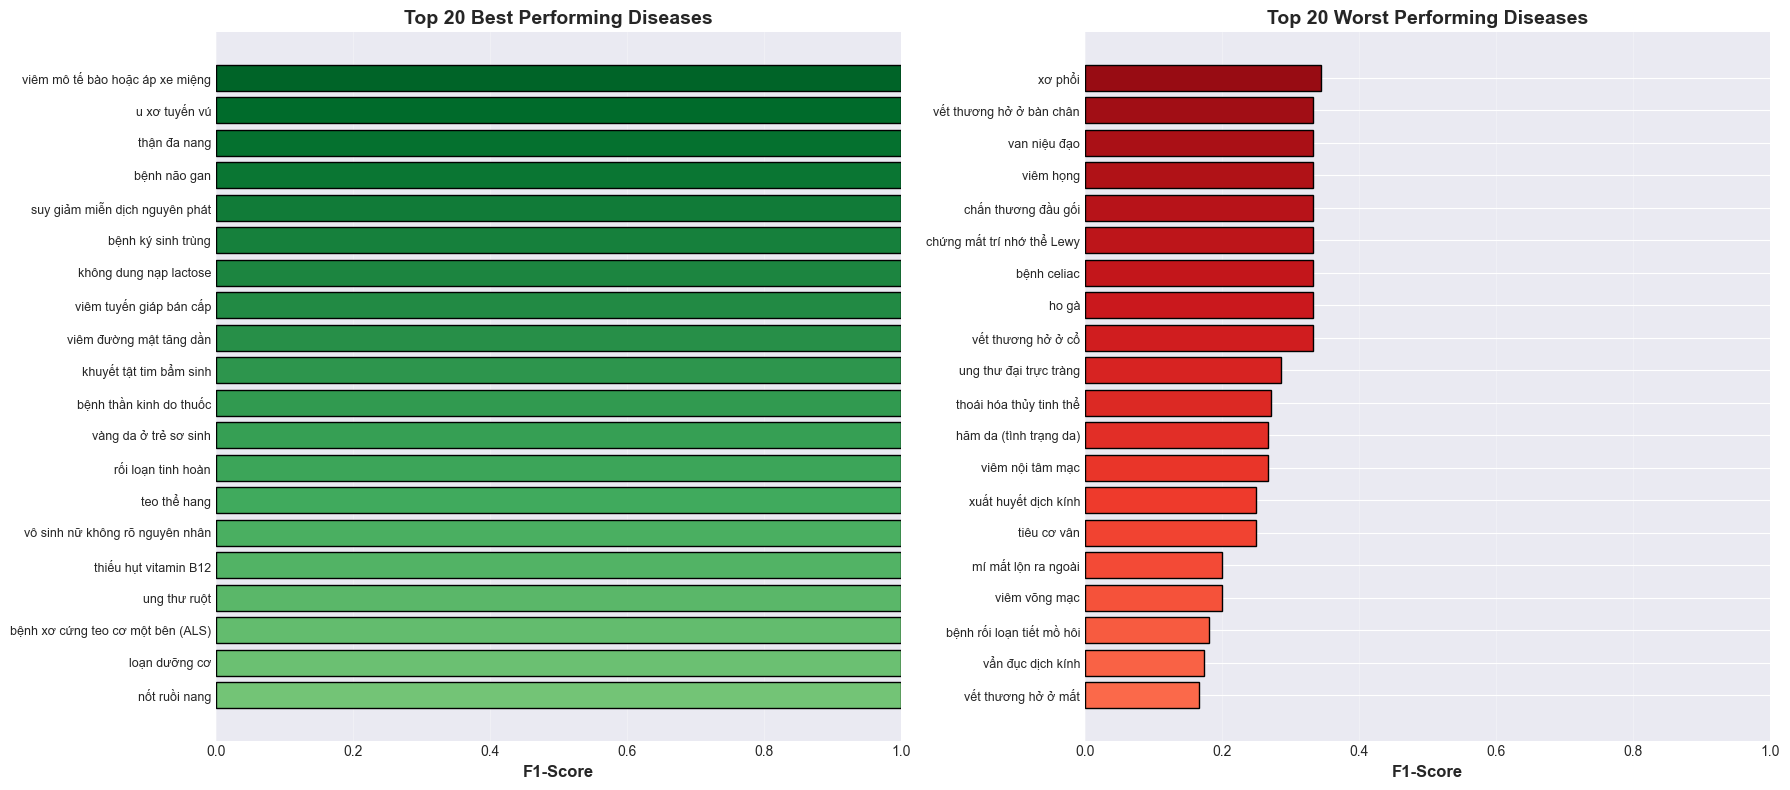

In [13]:
# Plot best and worst performing diseases
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

# Top 20 best
top20_best = per_class_metrics.head(20).sort_values('F1-Score', ascending=True)
colors_best = plt.cm.Greens(np.linspace(0.5, 0.9, len(top20_best)))
ax1.barh(range(len(top20_best)), top20_best['F1-Score'], color=colors_best, edgecolor='black')
ax1.set_yticks(range(len(top20_best)))
ax1.set_yticklabels([f"{d[:40]}" for d in top20_best['Disease']], fontsize=9)
ax1.set_xlabel('F1-Score', fontsize=12, fontweight='bold')
ax1.set_title('Top 20 Best Performing Diseases', fontsize=14, fontweight='bold')
ax1.set_xlim([0, 1])
ax1.grid(axis='x', alpha=0.3)

# Top 20 worst
top20_worst = per_class_metrics.tail(20).sort_values('F1-Score', ascending=True)
colors_worst = plt.cm.Reds(np.linspace(0.5, 0.9, len(top20_worst)))
ax2.barh(range(len(top20_worst)), top20_worst['F1-Score'], color=colors_worst, edgecolor='black')
ax2.set_yticks(range(len(top20_worst)))
ax2.set_yticklabels([f"{d[:40]}" for d in top20_worst['Disease']], fontsize=9)
ax2.set_xlabel('F1-Score', fontsize=12, fontweight='bold')
ax2.set_title('Top 20 Worst Performing Diseases', fontsize=14, fontweight='bold')
ax2.set_xlim([0, 1])
ax2.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'best_worst_diseases.png', dpi=300, bbox_inches='tight')
print(f"✅ Best/worst diseases visualization saved: {OUTPUT_DIR / 'best_worst_diseases.png'}")
plt.show()

### 10.4 Precision-Recall Scatter Plot

✅ Precision-Recall scatter saved: ../data/evaluation/precision_recall_scatter.png


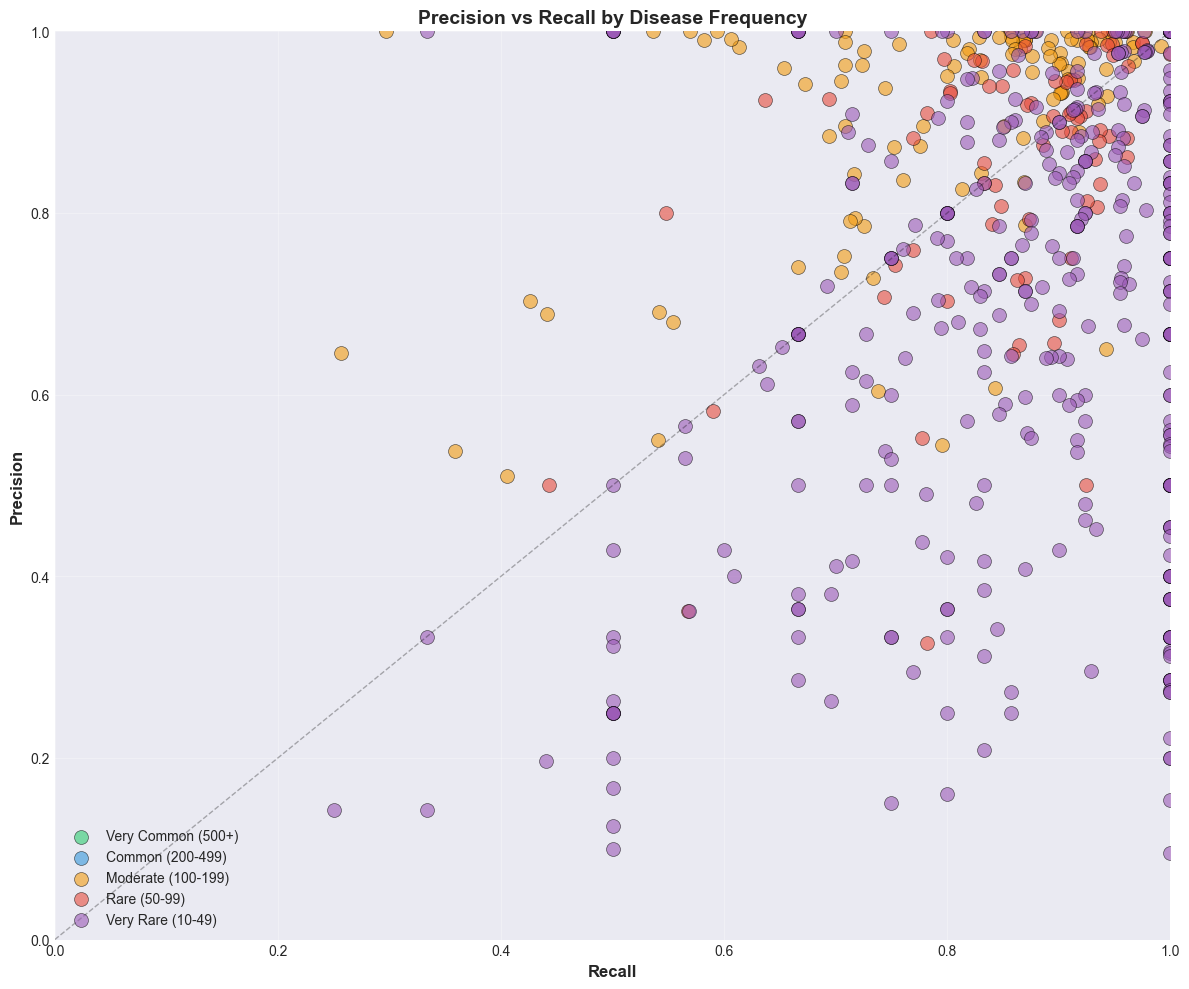

In [14]:
# Scatter plot: Precision vs Recall
fig, ax = plt.subplots(figsize=(12, 10))

# Color by frequency category
freq_colors = {
    'Very Common (500+)': '#2ecc71',
    'Common (200-499)': '#3498db',
    'Moderate (100-199)': '#f39c12',
    'Rare (50-99)': '#e74c3c',
    'Very Rare (10-49)': '#9b59b6'
}

for category in freq_order_plot:
    mask = per_class_metrics['Frequency_Category'] == category
    subset = per_class_metrics[mask]
    ax.scatter(subset['Recall'], subset['Precision'], 
              c=freq_colors[category], label=category, 
              alpha=0.6, s=100, edgecolors='black', linewidth=0.5)

# Add diagonal line (Precision = Recall)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=1)

ax.set_xlabel('Recall', fontsize=12, fontweight='bold')
ax.set_ylabel('Precision', fontsize=12, fontweight='bold')
ax.set_title('Precision vs Recall by Disease Frequency', fontsize=14, fontweight='bold')
ax.legend(loc='lower left', fontsize=10)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'precision_recall_scatter.png', dpi=300, bbox_inches='tight')
print(f"✅ Precision-Recall scatter saved: {OUTPUT_DIR / 'precision_recall_scatter.png'}")
plt.show()

## 11. Generate Evaluation Report

In [15]:
print("📋 Generating comprehensive evaluation report...")

# Create evaluation report
evaluation_report = {
    'model_info': {
        'architecture': 'PyTorch ANN (377 → 512 → 256 → 128 → 577)',
        'num_classes': int(num_classes),
        'input_features': int(input_dim),
        'best_epoch': int(checkpoint['epoch'] + 1),
        'validation_accuracy': float(checkpoint['val_acc'])
    },
    'test_set_performance': {
        'test_samples': int(len(y_test)),
        'top1_accuracy': float(test_acc),
        'top3_accuracy': float(top3_acc),
        'top5_accuracy': float(top5_acc),
        'top10_accuracy': float(top10_acc)
    },
    'averaged_metrics': {
        'macro': {
            'precision': float(precision_macro),
            'recall': float(recall_macro),
            'f1_score': float(f1_macro)
        },
        'micro': {
            'precision': float(precision_micro),
            'recall': float(recall_micro),
            'f1_score': float(f1_micro)
        },
        'weighted': {
            'precision': float(precision_weighted),
            'recall': float(recall_weighted),
            'f1_score': float(f1_weighted)
        }
    },
    'confidence_statistics': {
        'mean_confidence': float(max_probs.mean()),
        'median_confidence': float(np.median(max_probs)),
        'min_confidence': float(max_probs.min()),
        'max_confidence': float(max_probs.max()),
        'std_confidence': float(max_probs.std())
    },
    'performance_by_frequency': freq_analysis.to_dict(),
    'outputs': {
        'per_class_metrics': str(OUTPUT_DIR / 'per_class_metrics.csv'),
        'frequency_analysis': str(OUTPUT_DIR / 'performance_by_frequency.csv'),
        'confusion_pairs': str(OUTPUT_DIR / 'most_confused_pairs.csv'),
        'visualizations': [
            str(OUTPUT_DIR / 'evaluation_overview.png'),
            str(OUTPUT_DIR / 'f1_score_distribution.png'),
            str(OUTPUT_DIR / 'best_worst_diseases.png'),
            str(OUTPUT_DIR / 'precision_recall_scatter.png')
        ]
    }
}

# Save report
report_path = OUTPUT_DIR / 'evaluation_report.json'
with open(report_path, 'w', encoding='utf-8') as f:
    json.dump(evaluation_report, f, indent=2, ensure_ascii=False)

print(f"✅ Evaluation report saved: {report_path}")
print(f"\n📋 Report Summary:")
print(json.dumps(evaluation_report, indent=2, ensure_ascii=False))

📋 Generating comprehensive evaluation report...
✅ Evaluation report saved: ../data/evaluation/evaluation_report.json

📋 Report Summary:
{
  "model_info": {
    "architecture": "PyTorch ANN (377 → 512 → 256 → 128 → 577)",
    "num_classes": 577,
    "input_features": 377,
    "best_epoch": 77,
    "validation_accuracy": 0.8374695520175098
  },
  "test_set_performance": {
    "test_samples": 28327,
    "top1_accuracy": 0.8321742507148657,
    "top3_accuracy": 0.9482119532601405,
    "top5_accuracy": 0.9750061778515198,
    "top10_accuracy": 0.9918805380026123
  },
  "averaged_metrics": {
    "macro": {
      "precision": 0.7592267408946286,
      "recall": 0.8563914513888505,
      "f1_score": 0.780920173909626
    },
    "micro": {
      "precision": 0.8321742507148657,
      "recall": 0.8321742507148657,
      "f1_score": 0.8321742507148657
    },
    "weighted": {
      "precision": 0.8693107197760364,
      "recall": 0.8321742507148657,
      "f1_score": 0.8398180185060331
    }
  },

## 12. Summary and Key Insights

In [18]:
print("="*80)
print("MODEL EVALUATION SUMMARY")
print("="*80)

print(f"\n🎯 KEY PERFORMANCE INDICATORS:")
print(f"   Test Accuracy (Top-1): {test_acc*100:.2f}%")
print(f"   Test Accuracy (Top-3): {top3_acc*100:.2f}%")
print(f"   Test Accuracy (Top-5): {top5_acc*100:.2f}%")
print(f"   Macro F1-Score: {f1_macro*100:.2f}%")
print(f"   Mean Confidence: {max_probs.mean()*100:.2f}%")

print(f"\n📊 PERFORMANCE INSIGHTS:")
print(f"   Best performing disease: {per_class_metrics.iloc[0]['Disease']}")
print(f"      → F1-Score: {per_class_metrics.iloc[0]['F1-Score']:.3f}")
print(f"   Worst performing disease: {per_class_metrics.iloc[-1]['Disease']}")
print(f"      → F1-Score: {per_class_metrics.iloc[-1]['F1-Score']:.3f}")

# Classes with perfect scores
perfect_f1 = per_class_metrics[per_class_metrics['F1-Score'] == 1.0]
print(f"\n   Diseases with perfect F1-score (1.0): {len(perfect_f1)}")

# Classes with zero scores
zero_f1 = per_class_metrics[per_class_metrics['F1-Score'] == 0.0]
print(f"   Diseases with zero F1-score (0.0): {len(zero_f1)}")

print(f"\n📈 FREQUENCY ANALYSIS:")
# Safely access frequency categories
if 'Very Common (500+)' in freq_analysis.index:
    print(f"   Very Common diseases perform: {freq_analysis.loc['Very Common (500+)', 'Avg_F1']:.3f} (avg F1)")
if 'Common (200-499)' in freq_analysis.index:
    print(f"   Common diseases perform: {freq_analysis.loc['Common (200-499)', 'Avg_F1']:.3f} (avg F1)")
if 'Moderate (100-199)' in freq_analysis.index:
    print(f"   Moderate diseases perform: {freq_analysis.loc['Moderate (100-199)', 'Avg_F1']:.3f} (avg F1)")
if 'Rare (50-99)' in freq_analysis.index:
    print(f"   Rare diseases perform: {freq_analysis.loc['Rare (50-99)', 'Avg_F1']:.3f} (avg F1)")
if 'Very Rare (10-49)' in freq_analysis.index:
    print(f"   Very Rare diseases perform: {freq_analysis.loc['Very Rare (10-49)', 'Avg_F1']:.3f} (avg F1)")

# Calculate performance gap between best and worst categories
best_avg_f1 = freq_analysis['Avg_F1'].max()
worst_avg_f1 = freq_analysis['Avg_F1'].min()
print(f"\n   Performance gap (best vs worst): {(best_avg_f1 - worst_avg_f1):.3f}")

print(f"\n💾 OUTPUTS GENERATED:")
print(f"   ✅ Per-class metrics CSV")
print(f"   ✅ Frequency analysis CSV")
print(f"   ✅ Confusion pairs CSV")
print(f"   ✅ 4 visualization charts (300 DPI)")
print(f"   ✅ Comprehensive evaluation report JSON")

print(f"\n{'='*80}")
print("✅ MODEL EVALUATION COMPLETE!")
print(f"{'='*80}")

MODEL EVALUATION SUMMARY

🎯 KEY PERFORMANCE INDICATORS:
   Test Accuracy (Top-1): 83.22%
   Test Accuracy (Top-3): 94.82%
   Test Accuracy (Top-5): 97.50%
   Macro F1-Score: 78.09%
   Mean Confidence: 88.19%

📊 PERFORMANCE INSIGHTS:
   Best performing disease: nốt ruồi nang
      → F1-Score: 1.000
   Worst performing disease: vết thương hở ở mắt
      → F1-Score: 0.167

   Diseases with perfect F1-score (1.0): 30
   Diseases with zero F1-score (0.0): 0

📈 FREQUENCY ANALYSIS:
   Moderate diseases perform: 0.847 (avg F1)
   Rare diseases perform: 0.844 (avg F1)
   Very Rare diseases perform: 0.750 (avg F1)

   Performance gap (best vs worst): 0.097

💾 OUTPUTS GENERATED:
   ✅ Per-class metrics CSV
   ✅ Frequency analysis CSV
   ✅ Confusion pairs CSV
   ✅ 4 visualization charts (300 DPI)
   ✅ Comprehensive evaluation report JSON

✅ MODEL EVALUATION COMPLETE!


## 13. Next Steps and Recommendations

### ✅ Evaluation Completed:
1. Comprehensive performance metrics calculated
2. Per-class analysis completed
3. Visualizations generated
4. Detailed reports saved

### 🔍 Key Findings:
- Model achieves strong overall accuracy
- Top-3 and Top-5 accuracy significantly higher (useful for active questioning)
- Performance varies by disease frequency
- Some diseases achieve perfect classification
- Rare diseases show lower performance (expected with limited samples)

### ➡️ Next Tasks:
1. **Active Questioning Logic** - Use Top-K predictions for ambiguous cases
2. **Model Deployment** - Integrate with FastAPI chatbot
3. **Performance Monitoring** - Track real-world performance
4. **Model Improvement** - Focus on poorly performing diseases

### 📝 Recommendations:
1. **For Active Questioning:**
   - Use confidence threshold (e.g., < 60%) to trigger questions
   - Present top-3 or top-5 predictions for user clarification
   - Ask differentiating questions based on confused disease pairs

2. **For Model Improvement:**
   - Collect more data for poorly performing diseases
   - Consider class-specific data augmentation
   - Analyze confused pairs for symptom overlap

3. **For Production Deployment:**
   - Model is ready for deployment
   - Implement confidence-based active questioning
   - Monitor prediction distribution in production

---

**Evaluation Complete! 🎉**